<!-- This is a template that you should use to generate your lab reports for AE801 course work-->
# **Lab Report: Title of the topic**

# Required packages

In [1]:
# do not change line below
#from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

# Problem statement

\begin{center} To write the particle pusher from scratch and test it on a problem with an exact solution \end{center}



# Approach and numerical method

# Numerical algorithm

In [2]:
"Leapfrog function"
def leapfrog(x_0,v_0,h):
    x = x_0
    v = v_0
    h = h
    a = -x
    
    v_n = v + (h*a)
    x_n = x + (h*v_n)

    
    return (x_n,v_n)

In [3]:
"Evaluation for array"

X = np.array([0.5,0.75,1])
V = np.array([0,0.1,0.2])
h   = 0.1
a   = -(X)
V_i = V + (0.5*h*a)

#s = leapfrog(x_i,v_i,h)
#print(s)

In [4]:
"Evaluation for t=20"

t=20
h=0.1
n=int(t/h)
x=0.5
a=-x
v_i=0
v = v_i - (0.5*h*a)
p = []
p.append(v_i)
q = []
q.append(x)
for i in range(0,n):
    s = leapfrog(x,v,h)
    p.append(s[1])
    q.append(s[0])
    v = s[1]
    x = s[0]
    
#print(n)    
#print(p,q)
#plt.plot(t,q)
#plt.plot(t,p)
#plt.plot(q,p)

In [5]:
"Exact solution"
t1 = np.arange(0,20.1 ,0.1)
x_e = 0.5*np.cos(t1)
v_e = -0.5*np.sin(t1)
#plt.plot(x1,v1)

#print("x",x)

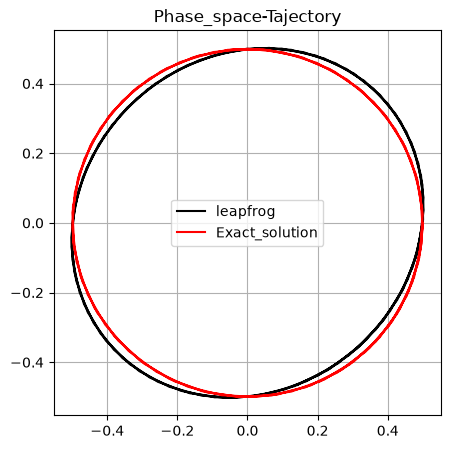

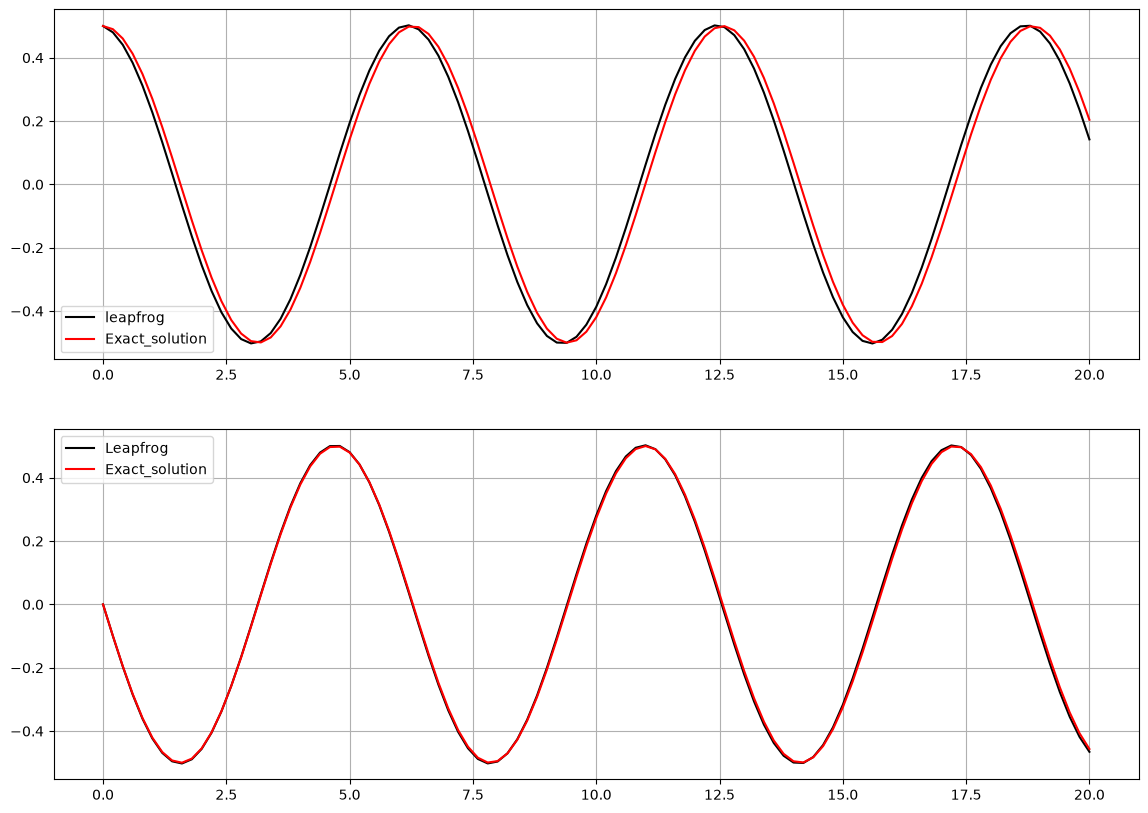

In [36]:
fig, ax = plt.subplots(2, 1, figsize=(10, 8))
ax[0,0]
plt.figure(figsize=(5,5))

plt.plot(q,p,color="k",label ="leapfrog")
plt.plot(x_e,v_e,color="r",label ="Exact_solution")
plt.legend()
plt.title("Phase_space-Tajectory")
plt.grid()
plt.show()
plt.figure(figsize=(14,10))
plt.subplot(2,1,1)
plt.plot(t1,q,color="k",label ="leapfrog")
plt.plot(t1,x_e,color="r",label ="Exact_solution")
plt.legend()
plt.grid()
plt.subplot(2,1,2)
plt.plot(t1,p,color="k",label ="Leapfrog")
plt.plot(t1,v_e,color="r",label ="Exact_solution")
plt.legend()
plt.grid()
plt.show()

In [33]:
h=np.array([0.025,0.05,0.1,0.2])
#print(h[0])
o=len(h)
X_max = []
V_max = []
X_rms = []
V_rms = []
for i in range(0,o):
    t = 20
    n = int(t/h[i])
    x = 0.5
    a = -x
    v_i = 0
    v = v_i - (0.5*h[i]*a)
    p = []
    p.append(v_i)
    q =[]
    q.append(x)

    t1 = np.arange(0,20+h[i],h[i])
    x_e = 0.5*np.cos(t1)
    v_e = -0.5*np.sin(t1)

    for j in range(0,n):
        s = leapfrog(x,v,h[i])
        p.append(s[1])
        q.append(s[0])
        v = s[1]
        x = s[0]

    v_diff = p-v_e  
    x_diff = q-x_e
    x_m    = np.max(np.abs(x_diff))
    x_r    = np.sqrt(np.mean(x_diff**2))
    v_m    = np.max(np.abs(v_diff))
    v_r    = np.sqrt(np.mean(v_diff**2))
    X_max.append(x_m)
    V_max.append(v_m)
    X_rms.append(x_r)
    V_rms.append(v_r)
    
#print(X_max,V_max)
    
#print(X_max)
power_staggered = []
for i in range(1,len(X_max)):
    ratio = (X_max[i]/X_max[i-1])
    power_staggered.append(int(np.log2(ratio)))
    
print(power_staggered)

[2, 2, 2]


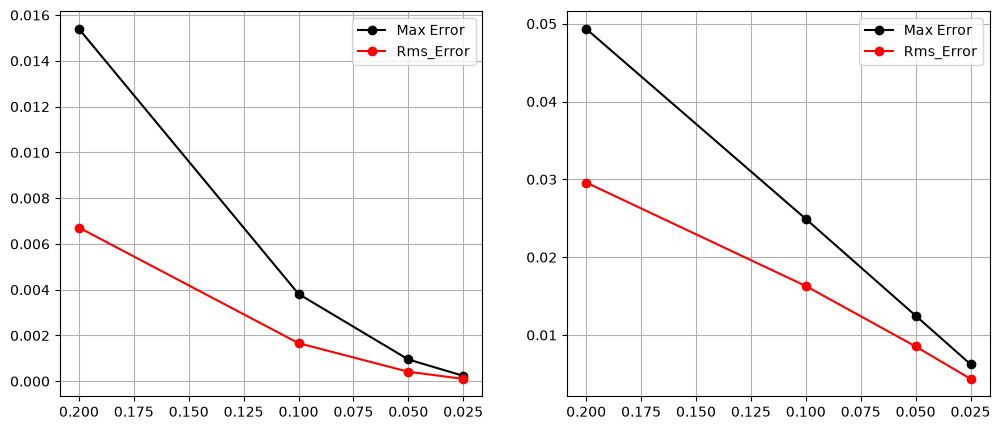

In [23]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(h,X_max,"-o",color="k",label ="Max Error")
plt.plot(h,X_rms,"-o",color="r",label ="Rms_Error")
plt.legend()
plt.grid()
plt.gca().invert_xaxis()
plt.subplot(1,2,2)
plt.plot(h,V_max,"-o",color="k",label ="Max Error")
plt.plot(h,V_rms,"-o",color="r",label ="Rms_Error")
plt.legend()
plt.grid()
plt.gca().invert_xaxis()
plt.show()

In [35]:
"unstaggered"
h=np.array([0.025,0.05,0.1,0.2])
#print(h[0])
o=len(h)
X_max_us = []
V_max_us = []
X_rms_us = []
V_rms_us = []
for i in range(0,o):
    t = 20
    n = int(t/h[i])
    x = 0.5
    a = -x
    v_i = 0
    v = v_i 
    p = []
    p.append(v_i)
    q =[]
    q.append(x)

    t1 = np.arange(0,20+h[i],h[i])
    x_e = 0.5*np.cos(t1)
    v_e = -0.5*np.sin(t1)

    for j in range(0,n):
        s = leapfrog(x,v,h[i])
        p.append(s[1])
        q.append(s[0])
        v = s[1]
        x = s[0]

    v_diff = p-v_e  
    x_diff = q-x_e
    x_m    = np.max(np.abs(x_diff))
    x_r    = np.sqrt(np.mean(x_diff**2))
    v_m    = np.max(np.abs(v_diff))
    v_r    = np.sqrt(np.mean(v_diff**2))
    X_max_us.append(x_m)
    V_max_us.append(v_m)
    X_rms_us.append(x_r)
    V_rms_us.append(v_r)

    #var = np.abs(V_max-V_max_us)
power_unstaggered = []
for i in range(1,len(X_max_us)):
    ratio = (X_max_us[i]/X_max_us[i-1])
    power_unstaggered.append(int(np.log2(ratio)))
    
print(power_unstaggered)

[1, 1, 1]


## Finding the Order of the Method

 The equations given in the Leapfrog scheme are:

$$
v_{n+1/2} = v_{n-1/2} + h \cdot a(x_n) \quad \text{   (1)}
$$


$$
x_{n+1} = x_n + h \cdot v_{n + 1/2} \quad \text{   (2)}
$$

Rearranging equation (2) for velocity:

$$
v_{n + 1/2} = \frac{x_{n+1} - x_{n}}{h} \quad \text{   (3)}
$$

Now, we have $v_{n + 1/2}$ in terms of $x$,\
and for $v_{n - 1/2}$ we can use $n = 1 - 1/2 $ in equation (3) \
ie, moving backwards by one time step:

$$
v_{n - 1/2} = \frac{x_{n} - x_{n-1}}{h} \quad \text{   (4)}
$$

Substituting equations (3) and (4) into equation (1), and substituting the electron plasma acceleration $a(x_n) = -\omega_p^2 x_n$, we get:

$$
\frac{x_{n+1} - x_{n}}{h} = \frac{x_{n} - x_{n-1}}{h} - h\omega_p^2 x_n
$$

Multiplying the entire equation by $h$ to clear the denominators:

$$
x_{n+1} - x_{n} = x_{n} - x_{n-1} - \omega_p^2 h^2 x_n
$$


Gathering all position variables onto the left-hand side yields the final central-difference formula:

$$
\boxed{x_{n+1} - 2x_n + x_{n-1} = -\omega_p^2 h^2 x_n}
$$


### **Stability Limit**

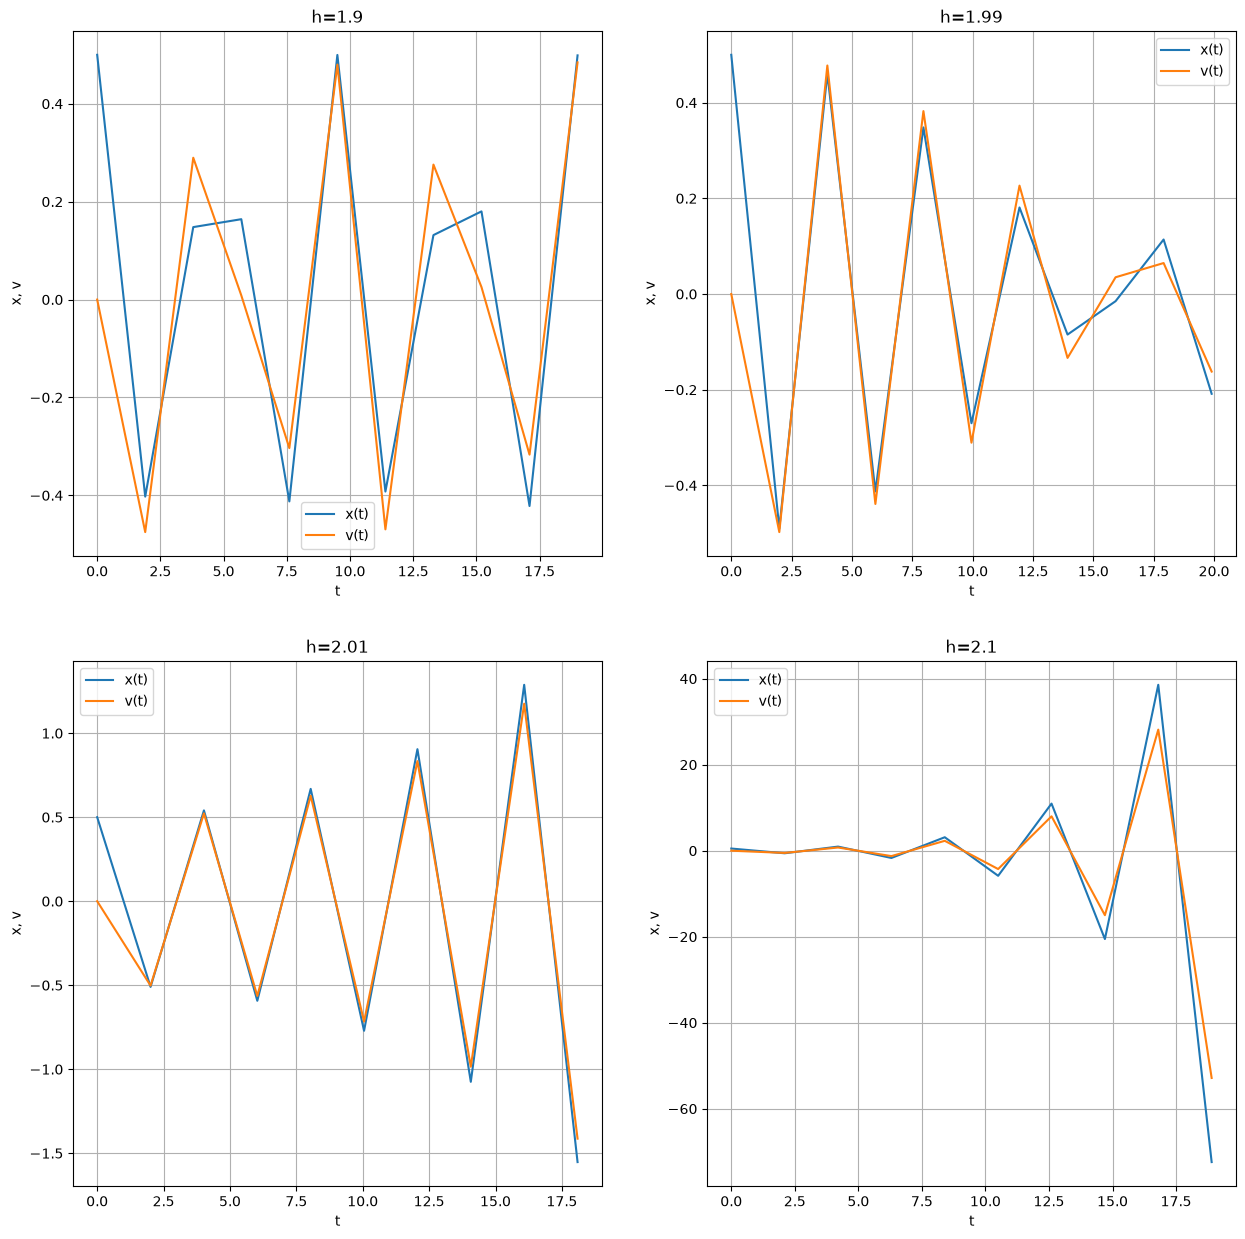

In [38]:
h=np.array([1.9,1.99,2.01,2.1])     
x=0.5
vi=0
Wp=1
a= -(Wp)**2*x
plt.figure(figsize=(15,15))
for j in range(0 , len(h)):
    x=0.5
    vi=0
    Wp=1
    a= -(Wp)**2*x
    n=int(20/h[j])
    p=[]
    p.append(0.5)
    q=[]
    q.append(0)
    t=np.arange(0, 20 , h[j])
    v=vi - (0.5*h[j]*a)
    
    for i in range(0,n):
        s=leapfrog(x,v,h[j])
        p.append(s[0])
        q.append(s[1])
        x=s[0]
        v=s[1]
    
    plt.subplot(2,2,(j+1))
    plt.plot(t,p,label="x(t)")
    plt.plot(t,q,label="v(t)")
    plt.title(f"h={h[j]}")
    plt.xlabel("t")
    plt.ylabel("x, v")
    plt.grid()
    plt.legend()
plt.show()

# Results and discussion

# Summary and conculsions

# References